# ¿Se puede predecir el mes exacto de conversión?

Comparamos modelos independientes por Z con distribuciones conjuntas y hazards.
**T=1 significa primer mes observado**, no un mes desde abrir la cuenta. Todos los
resultados usan train; no se lee test ni se produce una entrega nueva.

El protocolo está en `PROTOCOLO.md` y los ajustes comentados en `experimento.py`.
Este notebook verifica los resultados guardados; si faltan, ejecuta los experimentos.
Python 3.13. No hay early stopping ni ajuste contra las ventanas de evaluación.

In [2]:
from pathlib import Path
import json
import sys
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.calibration import calibration_curve

assert sys.version_info[:2] == (3, 13)
HERE = Path.cwd()
if not (HERE / "PROTOCOLO.md").exists():
    HERE = HERE / "nuevas-tareas" / "tiempo_conversion"
sys.path.insert(0, str(HERE))
from experimento import sha, binary_scores
OUT = HERE / "resultados"
if not (OUT / "manifiesto.json").exists():
    subprocess.run([sys.executable, str(HERE / "experimento.py")], check=True, cwd=HERE)
if not (OUT / "z11_sin_validacion.csv").exists():
    subprocess.run([sys.executable, str(HERE / "entrenar_z11.py")], check=True, cwd=HERE)
if not (OUT / "contrastes_exploratorios.json").exists():
    subprocess.run([sys.executable, str(HERE / "verificar.py")], check=True, cwd=HERE)
manifest = json.loads((OUT / "manifiesto.json").read_text(encoding="utf-8"))
assert manifest["script_sha256"] == sha(HERE / "experimento.py")
assert manifest["protocolo_sha256"] == sha(HERE / "PROTOCOLO.md")
assert manifest["train_sha256"] == sha(HERE.parents[1] / "train.csv")
assert manifest["historia_sha256"] == sha(HERE.parent / "experimentos.py")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
metrics = pd.read_csv(OUT / "metricas_mensuales.csv")
pred = pd.read_csv(OUT / "predicciones_mensuales.csv")
selected = manifest["seleccionado"]
display(pd.Series(json.loads((OUT / "auditorias.json").read_text()), name="Auditoría"))
print(f"Ajustes: {manifest['ajustes']}. Elegido antes de noviembre: {selected}.")

clientes                           24628
filas                             110100
gradiente_error                      0.0
claves                              True
contiguidad                         True
evento_terminal                     True
features_sin_etiqueta               True
features_invariantes_al_futuro      True
historia_invariante_al_futuro       True
identidad_pmf_hazard                True
Name: Auditoría, dtype: object

Ajustes: 122. Elegido antes de noviembre: Hazard_compartido.


## Formulaciones y dos tareas de evaluación

- **Exactos independientes:** P(T=Z), cada modelo usa cohortes maduras para Z.
- **CDF monótona:** P(T≤Z); se reconcilia con máximo acumulado y se diferencia.
- **Hazard separado:** P(T=Z | T≥Z), un modelo por duración.
- **Hazard compartido:** CatBoost con perfil inicial y duración.
- **Hazard logístico:** pendientes de perfil compartidas y efectos de duración.
- **PMF censurada:** softmax lineal; evento aporta log(p_T), censura aporta log(S_C).
- **KM sin perfil:** hazard empírico por duración, sin covariables.
- **Historia actual:** CatBoost con historia conocida al mes evaluado; control operacional.

Para evaluar el próximo mes entre sobrevivientes convertimos las masas exactas a hazard:
h_Z = p_Z / (1 − suma de p_j para j<Z). Para evaluar desde entrada usamos la PMF.
La clase de cola significa **conversión después del horizonte**, no «nunca convierte».

**Soporte común:** excluye solo duraciones todavía no observadas en entrenamiento.
**Todos:** para esas duraciones, las siete familias de tiempo utilizan el mismo respaldo
del hazard compartido, fuera del rango entrenado. Historia actual conserva su predicción.
El segundo resultado es híbrido y no valida la extrapolación de cada familia por separado.

,mes,n,sin_soporte,fraccion_sin_soporte
0,8,10050,3426,0.340896
1,9,9900,2995,0.302525
2,10,10400,2614,0.251346
3,11,9500,2259,0.237789


,mes_evaluado,maduros,positivos_exactos,positivos_acumulados,en_riesgo,eventos_riesgo,ultima_cohorte_madura
Z,,,,,,,
1,11,23900,3790,3790,23900,3790,10
2,11,22007,2965,6414,18558,2965,9
3,11,20708,2210,8219,14699,2210,8
4,11,18948,1697,9188,11457,1697,7
5,11,17998,1414,10134,9278,1414,6
6,11,16164,1003,10063,7104,1003,5
7,11,14191,725,9561,5355,725,4
8,11,13364,551,9559,4356,551,3
9,11,11321,418,8460,3279,418,2


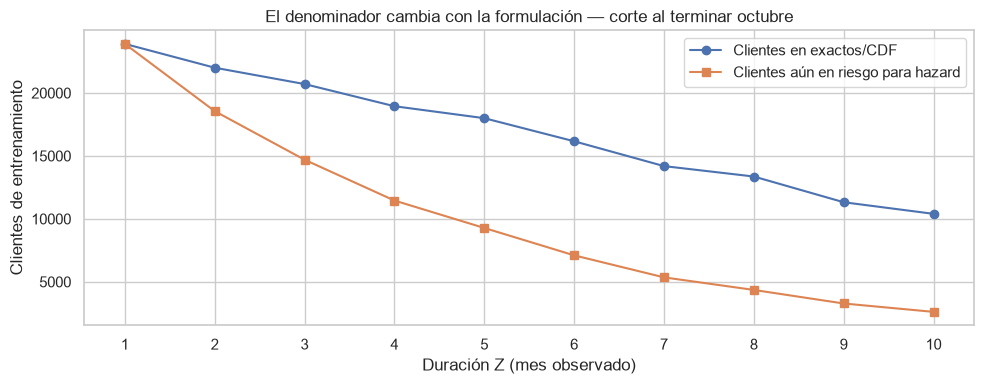

In [3]:
diagnostics = pd.read_csv(OUT / "diagnostics.csv")
sizes = pd.read_csv(OUT / "sizes.csv")
display(diagnostics[["mes", "n", "sin_soporte"]].assign(
    fraccion_sin_soporte=lambda d: d.sin_soporte/d.n))
display(sizes.loc[sizes.mes_evaluado.eq(11)].set_index("Z"))
# La madurez depende del horizonte potencial, no del número final de filas.
assert (sizes.ultima_cohorte_madura + sizes.Z - 1 < sizes.mes_evaluado).all()
fig, ax = plt.subplots(figsize=(10, 4))
s = sizes.loc[sizes.mes_evaluado.eq(11)]
ax.plot(s.Z, s.maduros, marker="o", label="Clientes en exactos/CDF")
ax.plot(s.Z, s.en_riesgo, marker="s", label="Clientes aún en riesgo para hazard")
ax.set(xlabel="Duración Z (mes observado)", ylabel="Clientes de entrenamiento",
       title="El denominador cambia con la formulación — corte al terminar octubre", xticks=s.Z)
ax.legend()
plt.tight_layout()
plt.show()

## Predicción mensual: selección agosto–octubre y comprobación en noviembre

Se selecciona por AUC media en soporte común, sin buscar hiperparámetros. Noviembre ya
fue explorado en sesiones anteriores: es una comprobación retrospectiva, no un test virgen.
La AUC de una distribución acumulada a tres meses no es comparable con esta AUC mensual.

mes,8,9,10,11,media_ago_oct
modelo,,,,,
Historia_actual,0.6400,0.6291,0.6356,0.6152,0.6349
Hazard_compartido,0.6369,0.6332,0.6339,0.6155,0.6347
Hazard_logistico,0.6293,0.6234,0.6236,0.6013,0.6255
Exactos_independientes,0.6306,0.6152,0.6226,0.6009,0.6228
Hazard_separado,0.6273,0.6176,0.6221,0.6017,0.6224
PMF_censurada,0.6237,0.6158,0.6125,0.5955,0.6173
CDF_monotona,0.6200,0.6094,0.6203,0.6092,0.6166
KM_sin_perfil,0.5192,0.5160,0.5252,0.5290,0.5202


,universo,modelo,n,AUC,Brier,LogLoss,tasa,pred_media
23,soporte_comun,Hazard_compartido,7241,0.615528,0.128970,0.421424,0.157851,0.146284
47,soporte_comun,Historia_actual,7241,0.615179,0.128851,0.421076,0.157851,0.154608
7,soporte_comun,CDF_monotona,7241,0.609152,0.130141,0.429908,0.157851,0.153750
39,soporte_comun,Hazard_separado,7241,0.601664,0.130142,0.426015,0.157851,0.146535
31,soporte_comun,Hazard_logistico,7241,0.601252,0.130601,0.427681,0.157851,0.147211
15,soporte_comun,Exactos_independientes,7241,0.600899,0.130386,0.426937,0.157851,0.142057
63,soporte_comun,PMF_censurada,7241,0.595535,0.130853,0.428583,0.157851,0.147029
55,soporte_comun,KM_sin_perfil,7241,0.529033,0.132873,0.435873,0.157851,0.147451
22,todos,Hazard_compartido,9500,0.617808,0.124818,0.410819,0.151474,0.140630
46,todos,Historia_actual,9500,0.617110,0.124746,0.410657,0.151474,0.148083


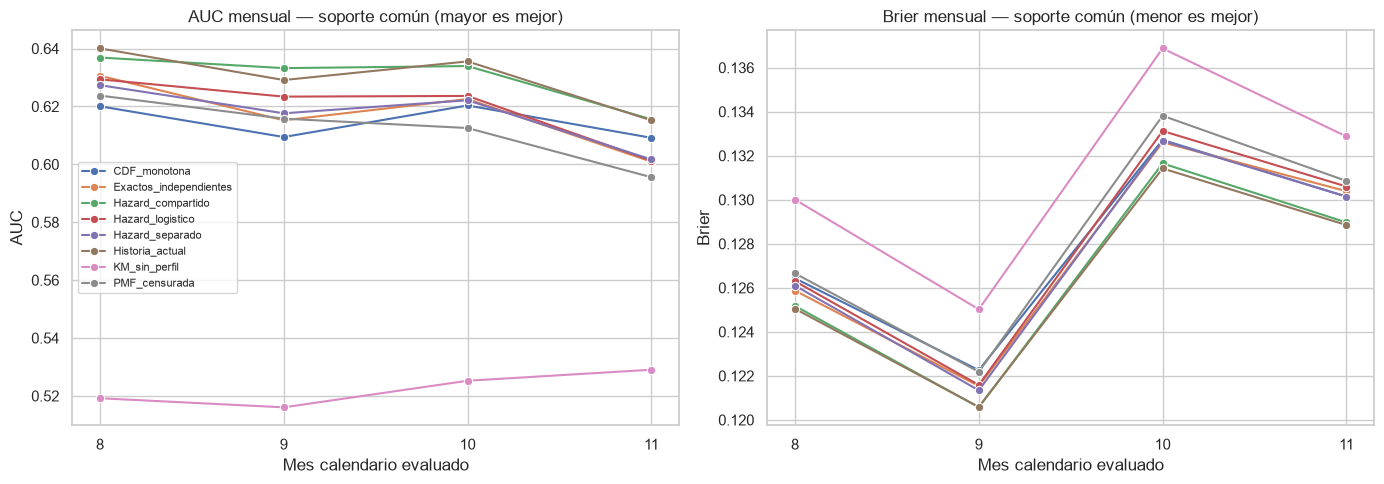

In [4]:
comparison = metrics.loc[metrics.universo.eq("soporte_comun")].pivot(
    index="modelo", columns="mes", values="AUC")
comparison["media_ago_oct"] = comparison[[8, 9, 10]].mean(axis=1)
display(comparison.sort_values("media_ago_oct", ascending=False).style.format("{:.4f}"))
nov = metrics.loc[metrics.mes.eq(11)]
display(nov[["universo", "modelo", "n", "AUC", "Brier", "LogLoss", "tasa", "pred_media"]]
        .sort_values(["universo", "AUC"], ascending=[True, False]))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric in zip(axes, ["AUC", "Brier"]):
    sns.lineplot(data=metrics.loc[metrics.universo.eq("soporte_comun")],
                 x="mes", y=metric, hue="modelo", marker="o", ax=ax)
    ax.set(xticks=[8, 9, 10, 11], xlabel="Mes calendario evaluado",
           title=f"{metric} mensual — soporte común ({'mayor' if metric=='AUC' else 'menor'} es mejor)")
    if metric == "Brier":
        ax.get_legend().remove()
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Coherencia probabilística: antes de reconciliar

Los clasificadores exactos independientes no garantizan que sus probabilidades sumen
como máximo uno. Los clasificadores acumulados no garantizan monotonía. Se auditan
esas propiedades **antes** de corregirlas. La corrección no equivale a calibración.
En los exactos, solo si la suma excede 1−1e-8 se reescala; el resto queda como cola.
En CDF, cada F_Z se reemplaza por el máximo de los F previos y el actual.

In [5]:
display(diagnostics[["mes", "suma_exactos_mayor_1", "suma_exactos_max", "cdf_no_monotona"]])
display(pd.read_csv(OUT / "convergence.csv"))
# Verificamos las distribuciones guardadas y la identidad usada para los hazards.
for month in [8, 9, 10, 11]:
    vectors = pd.read_csv(OUT / f"vectors_{month}.csv")
    assert vectors.p.ge(-1e-12).all()
    assert np.allclose(vectors.groupby(["modelo", "id_cliente"]).p.sum(), 1)
print("Todas las PMF reconciliadas son no negativas y suman uno; PMF censurada convergió en los cuatro cortes.")

,mes,suma_exactos_mayor_1,suma_exactos_max,cdf_no_monotona
0,8,0.004179,1.089377,0.062786
1,9,0.008586,1.141189,0.107677
2,10,0.014231,1.163131,0.151058
3,11,0.019789,1.173602,0.186211


,corte,convergio,mensaje,iteraciones,objetivo,max_gradiente
0,8,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,83,1.529242,1.255506e-06
1,9,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,90,1.592311,3.186238e-06
2,10,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL,88,1.675867,8.504124e-07
3,11,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL,89,1.726823,9.050048e-07


Todas las PMF reconciliadas son no negativas y suman uno; PMF censurada convergió en los cuatro cortes.


## Nuevos clientes: ¿en qué mes exacto convierten?

No hay clientes compartidos con entrenamiento. Se evalúa cada cohorte durante su
seguimiento completo: agosto permite Z=1..4; septiembre, 1..3; octubre, 1..2; noviembre,
solo Z=1. **No hay evidencia fuera de cohorte para los Z mayores que cuatro** en este diseño.
Se muestran también los clasificadores exactos sin reconciliar, tal como fueron entrenados.

modelo     CDF_monotona  Exactos_independientes  Exactos_sin_reconciliar  \
cohorte Z                                                                  
8       1        0.6292                  0.6292                   0.6292   
        2        0.6250                  0.6373                   0.6372   
        3        0.5409                  0.5570                   0.5569   
        4        0.5140                  0.5275                   0.5270   
9       1        0.6035                  0.6034                   0.6035   
        2        0.6044                  0.6113                   0.6110   
        3        0.5807                  0.5741                   0.5746   
10      1        0.6461                  0.6459                   0.6461   
        2        0.5822                  0.5681                   0.5685   
11      1        0.5821                  0.5820                   0.5821   

modelo     Hazard_compartido  Hazard_logistico  Hazard_separado  \
cohorte Z                                                         
8       1             0.6286            0.6219           0.6292   
        2             0.6328            0.6452           0.6336   
        3             0.5548            0.5513           0.5519   
        4             0.5002            0.5114           0.5168   
9       1             0.6138            0.6016           0.6035   
        2             0.6126            0.6082           0.6132   
        3             0.6024            0.5966           0.5753   
10      1             0.6495            0.6292           0.6461   
        2             0.5790            0.5585           0.5757   
11      1             0.5909            0.5752           0.5821   

modelo     KM_sin_perfil  PMF_censurada  
cohorte Z                                
8       1            0.5         0.6194  
        2            0.5         0.6280  
        3            0.5         0.5378  
        4            0.5         0.4995  
9       1            0.5         0.5944  
        2            0.5         0.6029  
        3            0.5         0.5939  
10      1            0.5         0.6302  
        2            0.5         0.5554  
11      1            0.5         0.5763

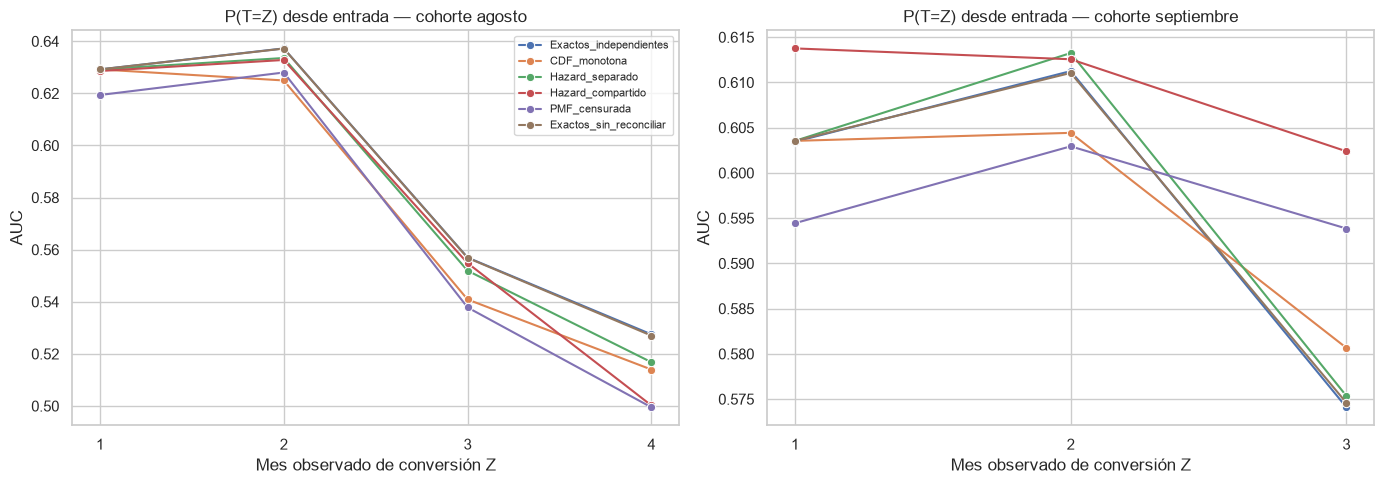

In [6]:
onset = pd.read_csv(OUT / "onset.csv")
display(onset.pivot_table(index=["cohorte", "Z"], columns="modelo", values="AUC").round(4))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
shown = ["Exactos_sin_reconciliar", "Exactos_independientes", "Hazard_compartido",
         "Hazard_separado", "PMF_censurada", "CDF_monotona"]
for ax, cohort in zip(axes, [8, 9]):
    view = onset.loc[onset.cohorte.eq(cohort) & onset.modelo.isin(shown)]
    sns.lineplot(data=view, x="Z", y="AUC", hue="modelo", marker="o", ax=ax)
    ax.set(xticks=sorted(view.Z.unique()), xlabel="Mes observado de conversión Z",
           title=f"P(T=Z) desde entrada — cohorte {'agosto' if cohort==8 else 'septiembre'}")
axes[0].legend(fontsize=8)
axes[1].get_legend().remove()
plt.tight_layout()
plt.show()

## Horizonte común de tres meses

Las clases son mes 1, mes 2, mes 3 y **sin evento dentro de tres meses**. Los binarios
maduros solo predicen conversión acumulada: no tienen log loss/Brier multiclase.
La log loss multiclase y el Brier multiclase se calculan sobre las cuatro clases;
el resto de las métricas corresponde al binario T≤3. Menor es mejor salvo AUC/AP.

,cohorte,modelo,n,AUC,Brier,LogLoss_multiclase,Brier_multiclase
4,8,Hazard_compartido,1760,0.657263,0.220894,1.079544,0.567001
8,8,Binario_maduro_3m,1760,0.656444,0.221800,NaN,NaN
1,8,CDF_monotona,1760,0.656442,0.221803,1.089963,0.569781
7,8,Multiclase_maduro_3m,1760,0.657705,0.222043,1.083886,0.568932
2,8,Hazard_separado,1760,0.659283,0.222060,1.085911,0.569422
0,8,Exactos_independientes,1760,0.660851,0.222166,1.085396,0.569370
5,8,Hazard_logistico,1760,0.657105,0.224903,1.090604,0.573423
6,8,PMF_censurada,1760,0.657865,0.225422,1.094725,0.574798
3,8,KM_sin_perfil,1760,0.500000,0.242887,1.129452,0.598445
13,9,Hazard_compartido,1299,0.664137,0.220269,1.092267,0.575281


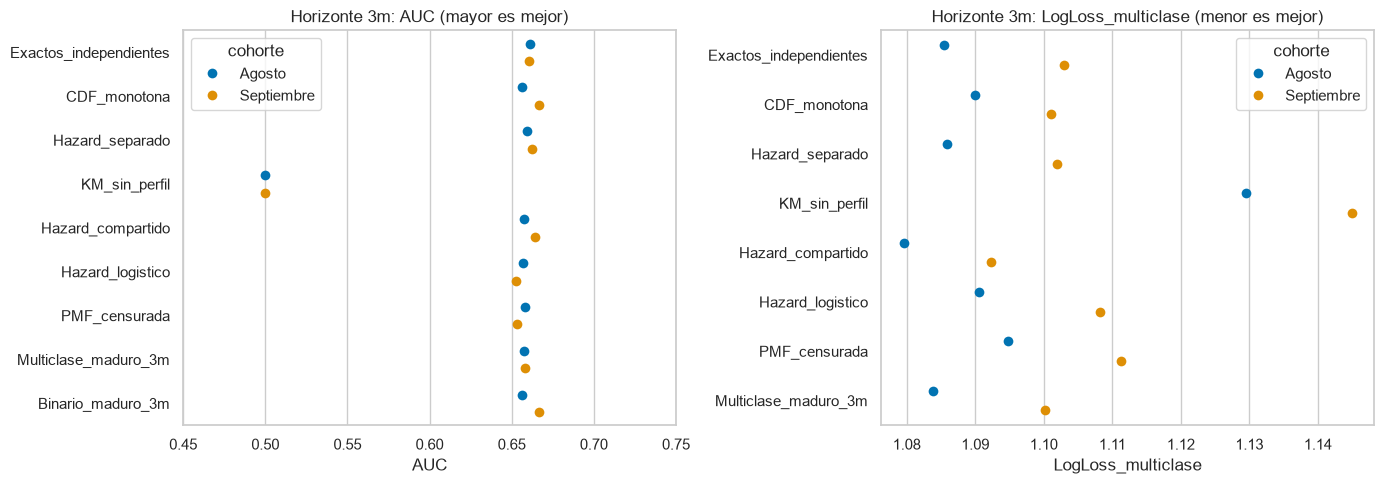

In [7]:
horizon = pd.read_csv(OUT / "horizon.csv")
display(horizon[["cohorte", "modelo", "n", "AUC", "Brier", "LogLoss_multiclase", "Brier_multiclase"]]
        .sort_values(["cohorte", "Brier"]))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, value in zip(axes, ["AUC", "LogLoss_multiclase"]):
    # Puntos, no barras truncadas: permiten ampliar diferencias sin distorsionar longitudes.
    plot_data = horizon.dropna(subset=[value]).assign(
        cohorte=lambda d: d.cohorte.map({8: "Agosto", 9: "Septiembre"}))
    sns.stripplot(data=plot_data, y="modelo", x=value, hue="cohorte", ax=ax,
                  orient="h", jitter=False, dodge=True, size=7, palette="colorblind")
    ax.set(title=f"Horizonte 3m: {value} ({'mayor' if value=='AUC' else 'menor'} es mejor)", ylabel="")
    if value == "AUC":
        ax.set_xlim(0.45, 0.75)
plt.tight_layout()
plt.show()

## Calibración y diferencias por duración

Las curvas de calibración usan diez grupos de igual cantidad de clientes, en noviembre
y soporte común. No se usan para recalibrar. Las AUC por duración permiten ver si el
ranking agregado se beneficia principalmente de distinguir duraciones distintas.

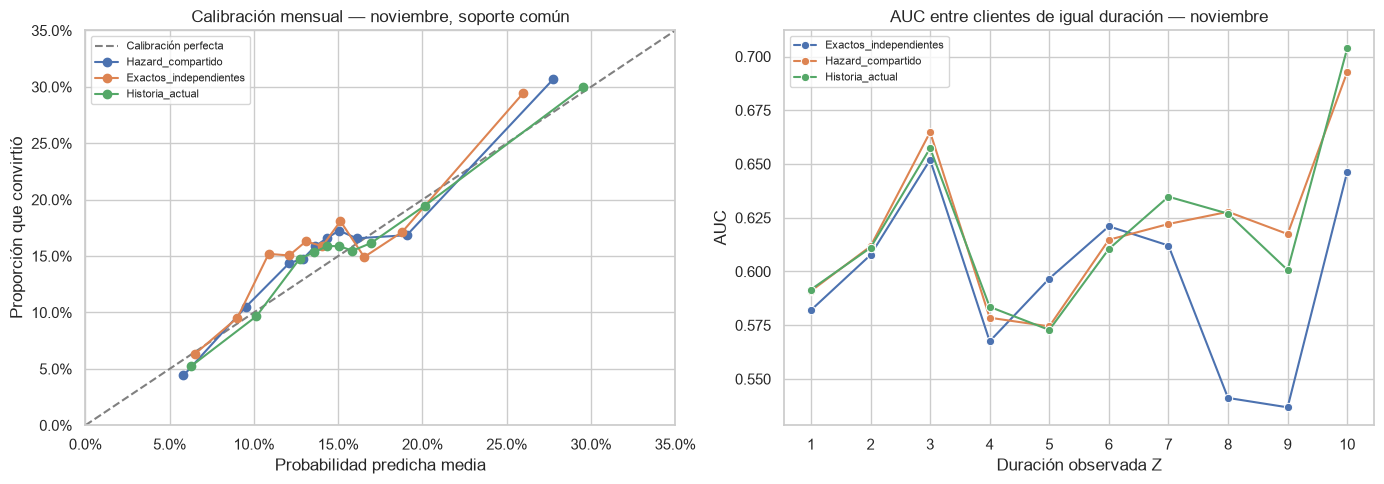

,modelo,universo,n,replicas,delta_AUC,IC_AUC_95,delta_Brier,IC_Brier_95
0,Exactos_independientes,soporte_comun,7241,1000,-0.014630,"[-0.024870488885616746, -0.004369667933507915]",0.001416,"[0.000889174254914645, 0.0019917657062160643]"
1,Exactos_independientes,todos,9500,1000,-0.011884,"[-0.020792055900832093, -0.003609713093901407]",0.001079,"[0.0006987639914379114, 0.0015068574313519298]"
2,Hazard_separado,soporte_comun,7241,1000,-0.013864,"[-0.02352175058132541, -0.003649185929900795]",0.001173,"[0.0006959752025886074, 0.0016938340178625192]"
3,Hazard_separado,todos,9500,1000,-0.010847,"[-0.019425284270917383, -0.003144882374955793]",0.000894,"[0.0005251668975177068, 0.0012720932233741648]"
4,Hazard_logistico,soporte_comun,7241,1000,-0.014276,"[-0.021975613103244893, -0.006642185773022471]",0.001631,"[0.0010897362137264003, 0.002150399861444146]"
5,Hazard_logistico,todos,9500,1000,-0.011232,"[-0.017380957574791283, -0.005355065649738886]",0.001243,"[0.0008351097403300878, 0.0016508664286386159]"
6,PMF_censurada,soporte_comun,7241,1000,-0.019994,"[-0.029573935656849935, -0.010529009355175594]",0.001883,"[0.0012432076395264427, 0.0025826131366278047]"
7,PMF_censurada,todos,9500,1000,-0.015688,"[-0.023182155261392726, -0.007925578650094531]",0.001435,"[0.0009709069326657864, 0.0018906031929790243]"
8,CDF_monotona,soporte_comun,7241,1000,-0.006377,"[-0.01953385388815713, 0.006040216076334078]",0.001172,"[0.00041977292771160584, 0.001878115675968443]"
9,CDF_monotona,todos,9500,1000,-0.005535,"[-0.015568972354052182, 0.004445371701309869]",0.000893,"[0.0003634640958088971, 0.001448711748858759]"


In [8]:
view = pred.loc[pred.mes.eq(11) & pred.soporte]
shown = list(dict.fromkeys([selected, "Exactos_independientes", "Hazard_compartido", "Historia_actual"]))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Calibración perfecta")
max_prob = .35
for name in shown:
    d = view.loc[view.modelo.eq(name)]
    observed, predicted = calibration_curve(d.y, d.p, n_bins=10, strategy="quantile")
    axes[0].plot(predicted, observed, marker="o", label=name)
    max_prob = max(max_prob, float(max(observed.max(), predicted.max()))*1.1)
axes[0].set(xlabel="Probabilidad predicha media", ylabel="Proporción que convirtió",
            title="Calibración mensual — noviembre, soporte común", xlim=(0, max_prob), ylim=(0, max_prob))
axes[0].xaxis.set_major_formatter(PercentFormatter(1))
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(fontsize=8)
by_z = pd.read_csv(OUT / "metricas_por_duracion.csv")
sns.lineplot(data=by_z.loc[by_z.mes.eq(11) & by_z.Z.le(10) & by_z.modelo.isin(shown)],
             x="Z", y="AUC", hue="modelo", marker="o", ax=axes[1])
axes[1].set(xlabel="Duración observada Z", title="AUC entre clientes de igual duración — noviembre", xticks=range(1, 11))
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
display(pd.DataFrame(json.loads((OUT / "contrastes_exploratorios.json").read_text(encoding="utf-8"))))

## Z=11: modelos entrenados, no validados

Para Z=11 solo enero tiene seguimiento suficiente. Los ajustes complementarios no
participaron en selección y no se presenta AUC de entrenamiento. Se guardan los tres
modelos con su manifiesto, pero no se predice diciembre con ellos en este experimento.

In [9]:
display(pd.read_csv(OUT / "z11_sin_validacion.csv"))
display(pd.Series(json.loads((OUT / "verificacion.json").read_text(encoding="utf-8")),
                  name="Verificación independiente de artefactos"))

,modelo,Z,clientes,positivos,tasa,cohortes_train,validado
0,Exacto_Z11,11,10400,296,0.028462,enero,False
1,Acumulado_Z11,11,10400,8437,0.811250,enero,False
2,Hazard_Z11,11,2259,296,0.131031,enero,False


metricas_mensuales            64
horizontes                    18
exactos_entrada               80
predicciones_mensuales    318800
etiquetas_y_soporte         True
hashes                      True
gradiente_auditado          True
Name: Verificación independiente de artefactos, dtype: object

## Interpretación y decisión

Las conclusiones siguientes se basan en resultados ejecutados, no en que una formulación
parezca más natural. El informe distingue resultados mensuales, horizonte y censura.

In [10]:
display(Markdown((HERE / "REPORTE_RESULTADOS.md").read_text(encoding="utf-8")))

# Modelos del tiempo de conversión: resultados

## Conclusión

**La propuesta es válida, pero los clasificadores independientes por mes exacto no mejoraron
la predicción mensual.** En las cuatro ventanas evaluadas, compartir información entre
duraciones con un único CatBoost de hazard superó tanto a los clasificadores exactos como
a los hazards separados. Las formulaciones conjuntas probabilísticas ensayadas tampoco
mejoraron ese control. No hay un salto sobre el nivel de discriminación mensual previo.

Se realizaron **122 ajustes evaluados**, más **3 ajustes complementarios para Z=11 sin
validación temporal**. Los tres últimos no participaron en selección ni en las métricas.
El notebook contiene los gráficos, las tablas completas y las comprobaciones.

## 1. Qué se probó y cómo se evitó la fuga

T=1 es el primer mes observado. La hipótesis de trabajo es que la foto inicial estaba
disponible antes de la primera etiqueta: se usan los 22 predictores de esa fila, no
promedios de toda la trayectoria ni la última fila. No se usa ID como predictor. Esto no
resuelve una eventual propagación hacia atrás ya presente en los CSV.

| Formulación | Etiqueta / likelihood | Entrenamiento |
|---|---|---|
| Exactos independientes | T=Z frente a T≠Z | Un CatBoost por Z; cohortes potencialmente maduras |
| CDF monótona | T≤Z | Un CatBoost por Z; mismas cohortes maduras; máximo acumulado para reconciliar |
| Hazard separado | Conversión en Z entre quienes llegaron a Z sin convertir | Un CatBoost por duración |
| Hazard compartido | Igual hazard, con duración como predictor | Un CatBoost sobre todos los intervalos observados |
| Hazard logístico | Igual hazard, con efectos categóricos de duración | Pendientes del perfil compartidas |
| PMF censurada | Evento: −log(p_T); censura en C: −log(S_C) | Softmax lineal conjunto con ridge y suavidad entre meses |
| KM sin perfil | Hazard empírico por duración | Sin variables del cliente |
| Historia actual | Conversión del mes | Control CatBoost con 33 features disponibles al mes evaluado |

Los CatBoost usan los mismos 250 árboles de profundidad 4 y parámetros fijos. No se hizo
early stopping, sobremuestreo ni selección de hiperparámetros sobre validación.
La PMF lineal y la logística tienen menos flexibilidad que los árboles: sus resultados
no invalidan todas las implementaciones posibles de supervivencia. La distinción entre
parametrizar PMF y hazard con likelihood de supervivencia está documentada en
[pycox](https://github.com/havakv/pycox#discrete-time-models); aquí se implementó una PMF
lineal con SciPy, sin instalar ni utilizar pycox/PyTorch.

Se entrenó hasta julio/agosto/septiembre/octubre para evaluar agosto/septiembre/octubre/
noviembre, respectivamente. La madurez de Z se exige **al corte del entrenamiento**, no
al final de todo el CSV. Nunca se incluyeron selectivamente conversores de cohortes inmaduras.
Para el modelo de Z, una conversión anterior es un negativo conocido; en hazard, ese
cliente ya salió del conjunto en riesgo. Los sobrevivientes observados hasta Z también
son negativos aunque no sepamos si convierten después.

**Dos poblaciones diferentes:** la validación mensual permite que un sobreviviente tenga
historia anterior en train, tal como ocurriría en operación; no se entrena con su futuro.
La evaluación desde entrada usa cohortes nuevas con clientes totalmente ausentes de train.

## 2. Comparación mensual principal: duraciones con soporte

En noviembre hay 7.241 clientes con duración 1..10 evaluable sin extrapolar. Los otros
2.259 están en su mes 11, que todavía no existía en el entrenamiento hasta octubre.

| Modelo | AUC media ago–oct | AUC noviembre | Brier noviembre ↓ |
|---|---:|---:|---:|
| Historia actual — control operacional | 0.6349 | 0.6152 | **0.12885** |
| **Hazard compartido — elegido antes de noviembre** | **0.6347** | **0.6155** | 0.12897 |
| Hazard logístico | 0.6255 | 0.6013 | 0.13060 |
| Exactos independientes | 0.6228 | 0.6009 | 0.13039 |
| Hazard separado | 0.6224 | 0.6017 | 0.13014 |
| PMF censurada | 0.6173 | 0.5955 | 0.13085 |
| CDF monótona | 0.6166 | 0.6092 | 0.13014 |
| KM sin perfil | 0.5202 | 0.5290 | 0.13287 |

La selección solo consideró las familias propuestas; Historia actual y KM son controles.
El resultado favorece compartir señal entre duraciones, no multiplicar los modelos. Es
compatible con menor variabilidad de estimación y más datos por patrón, pero no demuestra
cuál es el mecanismo: no se realizó una descomposición formal de sesgo y varianza.

Los exactos pierden **0.0146 de AUC** respecto al hazard compartido en noviembre, con
**IC bootstrap 95% [−0.0249, −0.0044]**. Para hazard separado, ΔAUC=−0.0139 e IC
[−0.0235, −0.0036]. Para Historia actual, ΔAUC=−0.00035 e IC [−0.0046, +0.0041]:
no hay una diferencia concluyente frente al compartido. Los intervalos y las restantes diferencias se guardan en
`resultados/contrastes_exploratorios.csv`. Son contrastes descriptivos sin ajuste por
multiplicidad, con 1.000 réplicas por cliente; condicionan a los modelos ya ajustados.

**Calibración:** en soporte común la tasa real es 15,79%; el hazard compartido predice
14,63%, los exactos 14,21% y el control con historia 15,46%. El ranking ligeramente mejor
del compartido no implica una mejor calibración. Historia actual mantiene Brier y log
loss ligeramente inferiores. No se recalibró contra noviembre.

### Todos los clientes de noviembre

Para los 2.259 clientes fuera de soporte, las siete familias de tiempo usan **el mismo
respaldo del hazard compartido**, aplicado fuera del rango entrenado. Son resultados
híbridos, no evidencia de extrapolación propia de cada familia:

| Modelo / híbrido | AUC | Brier ↓ |
|---|---:|---:|
| Hazard compartido | 0.6178 | 0.12482 |
| Historia actual, sin reemplazar sus predicciones | 0.6171 | 0.12475 |
| CDF monótona + respaldo | 0.6123 | 0.12571 |
| Hazard separado + respaldo | 0.6070 | 0.12571 |
| Hazard logístico + respaldo | 0.6066 | 0.12606 |
| Exactos independientes + respaldo | 0.6059 | 0.12590 |
| PMF censurada + respaldo | 0.6021 | 0.12625 |

El respaldo afecta al **23,78%** de noviembre; no es una fracción despreciable. En agosto
afecta al 34,09%. Por eso la selección se hizo sobre soporte común. No se comparan estos
números como mejoras directas contra experimentos anteriores con otra capacidad/modelo.

## 3. Incoherencias de los clasificadores independientes

En noviembre, **1,98%** de las PMF crudas sumaban más de uno, con un máximo de **117,36%**.
Se reescalaron solo esas distribuciones para obtener masas válidas y una cola residual.
La proporción pasó de 0,42% en agosto a 1,98% en noviembre. Esta corrección es heurística;
no demuestra que la cola quede bien calibrada.

En la formulación acumulada, **18,62%** de los clientes de noviembre tenían al menos una
violación F(Z+1)<F(Z), frente a 6,28% en agosto. El máximo acumulado evita probabilidades
negativas al diferenciar, pero puede producir masas exactamente cero. Esto ayuda a entender
por qué una CDF con AUC aceptable no necesariamente da buena log loss mensual: en noviembre
su log loss en soporte es **0.42991**, frente a **0.42142** del hazard compartido.

Las probabilidades originales y reconciliadas se guardaron por cliente. No se confundió
P(T=Z) con el hazard al puntuar a clientes que ya sobrevivieron varios meses.

## 4. Desde entrada: ¿hay señal para el mes exacto?

Se evaluaron cohortes totalmente nuevas. Agosto tiene cuatro meses de seguimiento,
septiembre tres, octubre dos y noviembre uno. No se descartan usuarios por su desenlace.

Ejemplos de AUC de los **exactos crudos**, antes de reconciliar:

| Cohorte | Z=1 | Z=2 | Z=3 | Z=4 |
|---|---:|---:|---:|---:|
| Agosto, 1.760 clientes | 0.6292 | 0.6372 | 0.5569 | 0.5270 |
| Septiembre, 1.299 clientes | 0.6035 | 0.6110 | 0.5746 | No observable |
| Octubre, 1.893 clientes | 0.6461 | 0.5685 | No observable | No observable |
| Noviembre, 728 clientes | 0.5821 | No observable | No observable | No observable |

Hay señal para algunos meses tempranos, pero no una ventaja estable: en septiembre, para
Z=3 el hazard compartido convertido a PMF logra **0.6024**, frente a **0.5746** del exacto.
En agosto Z=4, el exacto mejora el punto estimado (0.5270 frente a 0.5002), pero ambos son
débiles y hay solo 143 eventos. No hay base para concluir que se identifica bien el mes
exacto ni para generalizar ese caso aislado. Tampoco se ha validado desde entrada Z>4.

### Horizonte común de tres meses

| Modelo | AUC T≤3, agosto / septiembre | Log loss 4 clases, agosto / septiembre ↓ |
|---|---|---|
| Hazard compartido | 0.6573 / 0.6641 | **1.0795 / 1.0923** |
| Exactos independientes | 0.6609 / 0.6606 | 1.0854 / 1.1030 |
| Hazard separado | 0.6593 / 0.6623 | 1.0859 / 1.1019 |
| CDF monótona | 0.6564 / 0.6667 | 1.0900 / 1.1011 |
| PMF censurada | 0.6579 / 0.6535 | 1.0947 / 1.1113 |
| Multiclase con cohortes maduras | 0.6577 / 0.6583 | 1.0839 / 1.1002 |
| Binario con cohortes maduras | 0.6564 / 0.6667 | No aplica |

No hay ganador estable por AUC acumulada. El hazard compartido tiene la menor log loss
y el menor Brier de cuatro clases en ambas cohortes. Es una ventaja descriptiva sobre
dos cohortes, no una prueba universal de superioridad. La cuarta clase es «sin evento en
3 meses», no «nunca». Todas estas métricas usan horizontes completos: no requieren inventar
desenlaces ni puntuar censurados como negativos de por vida.

## 5. Z=11: entrenable, pero no validable temporalmente con estos CSV

Se dejaron tres modelos complementarios usando train completo:

| Modelo Z=11 | Clientes | Positivos | Tasa |
|---|---:|---:|---:|
| Exacto: T=11 | 10.400 | 296 | 2,85% |
| Acumulado: T≤11 | 10.400 | 8.437 | 81,13% |
| Hazard: T=11 entre quienes alcanzaron 11 | 2.259 | 296 | 13,10% |

Todos dependen de enero. El mismo grupo de 296 positivos da una tasa de 2,85% o 13,10%
según el denominador: son preguntas distintas. Los archivos `.cbm` están en
`modelos_z11_sin_validacion/`. No se reporta AUC de entrenamiento ni se afirma capacidad
de generalizar a otra cohorte. Para el tiempo desde entrada, enero además representa
el comienzo de observación disponible, no necesariamente el comienzo real del riesgo.

## 6. Límites y decisión

- Mantener un hazard compartido como punto de partida; el control con historia sigue siendo
  competitivo. Esta sesión no justifica reemplazar la entrega ni promover un ganador nuevo.
- No descartar toda la familia PMF: aquí fue lineal regularizada y convergió en los cuatro
  cortes (gradiente máximo menor a 3,2e-6). Su menor AUC no se debió a un fallo de convergencia,
  pero su capacidad no coincide con la de un modelo neuronal o un ensamble no lineal.
- El uso de censura en likelihood presupone que el proceso de observación no añade información
  sobre T una vez consideradas las variables y la población modelada. La censura es administrativa,
  pero las cohortes y el calendario pueden tener diferencias no absorbidas por la foto inicial.
- Los clasificadores maduros también cambian de población al aumentar Z. Excluir cohortes
  incompletas evita etiquetas falsas, pero no elimina el cambio de distribución entre cohortes.
- Se mantuvieron una semilla y una configuración por familia. Los intervalos bootstrap no
  incorporan variabilidad de reentrenar ni corrigen exploraciones previas sobre noviembre.
- Sin timestamps de procedencia, ninguna partición puede certificar que las covariables estáticas
  no contienen una foto tomada después del momento de predicción. Esta limitación sigue abierta.

**Resultado práctico:** esta prueba refuerza que el perfil sirve más para ordenar propensión
que para ubicar con precisión el mes de conversión. Es una conclusión sobre los experimentos
realizados, no una demostración de un techo irrebasable de AUC.

## Reproducción y controles

Desde la raíz del proyecto, con el entorno existente de Python 3.13:

```powershell
.venv\Scripts\python.exe nuevas-tareas\tiempo_conversion\experimento.py
.venv\Scripts\python.exe nuevas-tareas\tiempo_conversion\entrenar_z11.py
.venv\Scripts\python.exe nuevas-tareas\tiempo_conversion\verificar.py
.venv\Scripts\python.exe nuevas-tareas\tiempo_conversion\ejecutar_notebook.py
```

Los controles comprueban claves, contigüidad, terminalidad, independencia de etiquetas,
invariancia al quitar el futuro, madurez al corte y separación por cliente en cohortes nuevas.
El gradiente de la likelihood censurada se contrastó con diferencias finitas (error 5,7e-8).
Las métricas se recalcularon desde las predicciones; se comprobaron las masas y su conversión
a hazard. `resultados/` contiene hashes, selección congelada antes de noviembre, métricas,
scores originales, distribuciones, tiempos de ajuste y contrastes. No se leyó `test.csv`
ni se cambió ninguna entrega o experimento anterior.
